***User input Dataset for clustering***

In [ ]:
import pandas as pd

# Load your dataset (adjust the file path as needed)
df = pd.read_csv('/content/user_input(Responses) - Form responses 1.csv')
# Check for missing values
print(df.isnull().sum())
# Drop duplicates
df = df.drop_duplicates()
df

Unnamed: 0                                                        126
Type your Name                                                      0
Enter your Age                                                      0
Gender                                                              0
Enter your Weight in Kg                                             0
Enter your Height in cm                                             0
  Activity Level                                                    0
  Diet Goal                                                         0
  List any dietary restrictions, allergies, or food dislikes       13
dtype: int64


,Unnamed: 0,Type your Name,Enter your Age,Gender,Enter your Weight in Kg,Enter your Height in cm,Activity Level,Diet Goal,"List any dietary restrictions, allergies, or food dislikes"
0,NaN,Deepthi B R,22,Female,40.0,150,Moderately active,Gain Weight,Little allergy in blood
1,NaN,Shashi Kiran,27,Male,74.0,167,Lightly active,Lose Weight,No
2,NaN,B V DEEPIKAPOORNIMA,23,Female,52.0,5.4,Moderately active,Maintain Weight,No
3,NaN,Jayasuriya p,24,Male,69.0,168,Moderately active,Maintain Weight,NaN
4,NaN,Santhosh Gowda,22,Male,62.0,171,Moderately active,Maintain Weight,"milk, eggs, shellfish, fish, peanuts, tree nut..."
...,...,...,...,...,...,...,...,...,...
121,NaN,R Sunil Kumar,34,Male,78.0,170.68,Very active,Maintain Weight,Chicken
122,NaN,Aakruthi gowda,20,Female,57.0,153,Very active,Maintain Weight,Peanut
123,NaN,Arvind R,24,Male,80.0,185,Very active,Maintain Weight,NaN
124,NaN,Suma Prakash,25,Female,54.0,167,Very active,Lose Weight,No


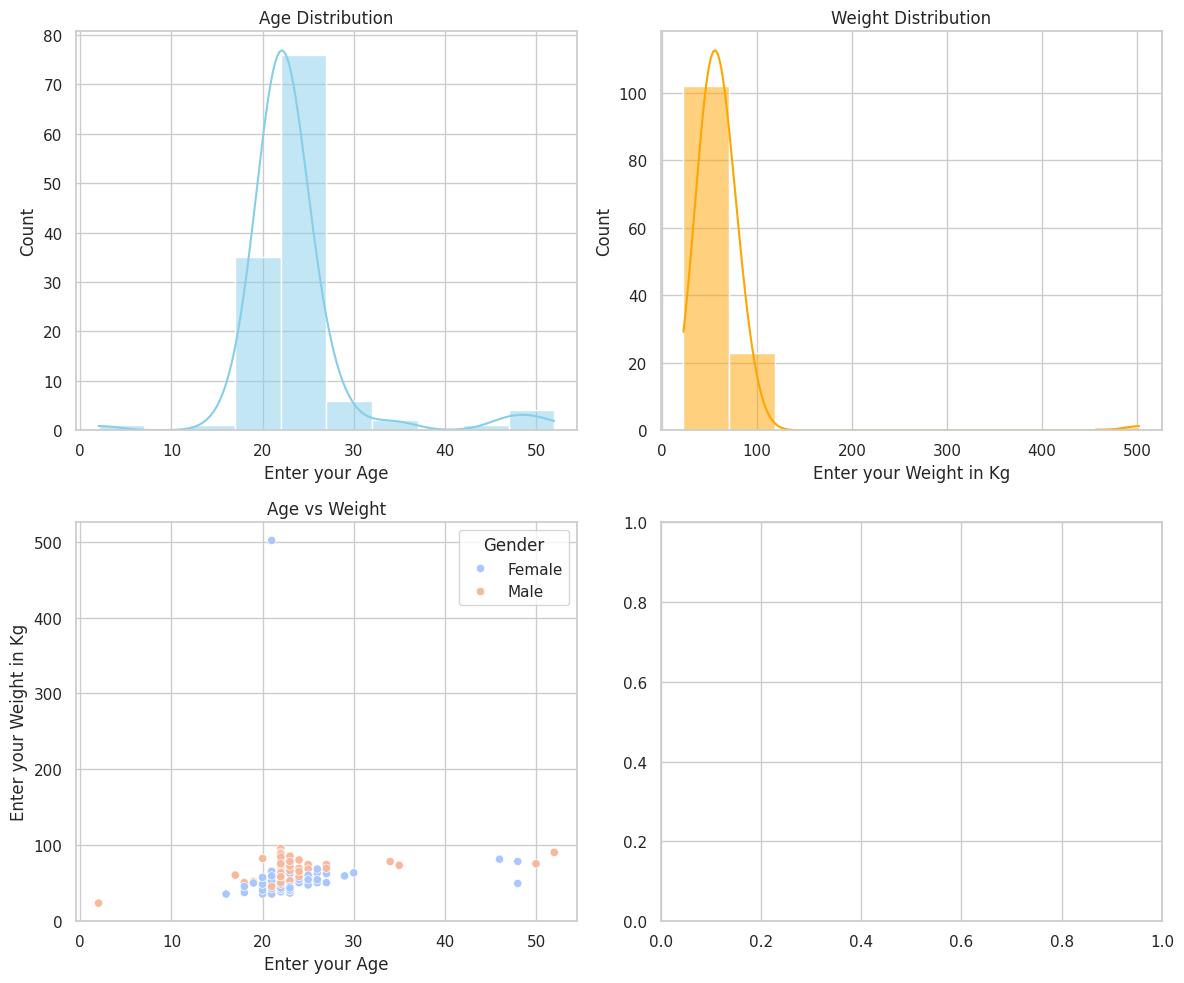

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style
sns.set(style="whitegrid")
# Create a figure with multiple subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
# Histogram for Age Distribution
sns.histplot(df["Enter your Age"], bins=10, kde=True, ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("Age Distribution")
# Histogram for Weight Distribution
sns.histplot(df["Enter your Weight in Kg"], bins=10, kde=True, ax=axes[0, 1], color="orange")
axes[0, 1].set_title("Weight Distribution")
# Scatter Plot: Age vs Weight
sns.scatterplot(data=df, x="Enter your Age", y="Enter your Weight in Kg", hue="Gender", palette="coolwarm", ax=axes[1, 0])
axes[1, 0].set_title("Age vs Weight")
plt.tight_layout()
plt.show()


***Cleaning the Dataset***

In [ ]:
# Drop
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
# Rename the last column to "allirgies"
df = df.rename(columns={"List any dietary restrictions, allergies, or food dislikes": "allirgies"})
# Verify changes
df.head()

,Type your Name,Enter your Age,Gender,Enter your Weight in Kg,Enter your Height in cm,Activity Level,Diet Goal,"List any dietary restrictions, allergies, or food dislikes"
0,Deepthi B R,22,Female,40.0,150,Moderately active,Gain Weight,Little allergy in blood
1,Shashi Kiran,27,Male,74.0,167,Lightly active,Lose Weight,No
2,B V DEEPIKAPOORNIMA,23,Female,52.0,5.4,Moderately active,Maintain Weight,No
3,Jayasuriya p,24,Male,69.0,168,Moderately active,Maintain Weight,NaN
4,Santhosh Gowda,22,Male,62.0,171,Moderately active,Maintain Weight,"milk, eggs, shellfish, fish, peanuts, tree nut..."


In [ ]:
# Drop the "Type your Name" column
df = df.drop(columns=['Type your Name'])
# Verify changes by displaying the first few rows
df.head()

,Enter your Age,Gender,Enter your Weight in Kg,Enter your Height in cm,Activity Level,Diet Goal,"List any dietary restrictions, allergies, or food dislikes"
0,22,Female,40.0,150,Moderately active,Gain Weight,Little allergy in blood
1,27,Male,74.0,167,Lightly active,Lose Weight,No
2,23,Female,52.0,5.4,Moderately active,Maintain Weight,No
3,24,Male,69.0,168,Moderately active,Maintain Weight,NaN
4,22,Male,62.0,171,Moderately active,Maintain Weight,"milk, eggs, shellfish, fish, peanuts, tree nut..."


In [ ]:
# Define new column names (ensure the list length matches the number of columns)
new_columns = [ 'Age', 'Gender', 'Weight_kg', 'Height_cm', 'Activity_Level', 'Diet_Goal', 'Allergies']
# Assign the new column names
df.columns = new_columns
# Verify the change
df.head()

,Age,Gender,Weight_kg,Height_cm,Activity_Level,Diet_Goal,Allergies
0,22,Female,40.0,150,Moderately active,Gain Weight,Little allergy in blood
1,27,Male,74.0,167,Lightly active,Lose Weight,No
2,23,Female,52.0,5.4,Moderately active,Maintain Weight,No
3,24,Male,69.0,168,Moderately active,Maintain Weight,NaN
4,22,Male,62.0,171,Moderately active,Maintain Weight,"milk, eggs, shellfish, fish, peanuts, tree nut..."


***Feature engineering***

In [ ]:
# Check data types
print(df[['Weight_kg', 'Height_cm']].dtypes)
# Convert weight and height to numeric (if needed)
df['Weight_kg'] = pd.to_numeric(df['Weight_kg'], errors='coerce')
df['Height_cm'] = pd.to_numeric(df['Height_cm'], errors='coerce')
#Compute BMI
df['bmi'] = df['Weight_kg'] / ((df['Height_cm'] / 100) ** 2)
# Verify the new BMI column
print(df[['Weight_kg', 'Height_cm', 'bmi']].head())

Weight_kg    float64
Height_cm     object
dtype: object
   Weight_kg  Height_cm           bmi
0       40.0      150.0     17.777778
1       74.0      167.0     26.533759
2       52.0        5.4  17832.647462
3       69.0      168.0     24.447279
4       62.0      171.0     21.203105


In [ ]:
def calculate_bmr(row):
    weight = row['Weight_kg']
    height = row['Height_cm']
    age = row['Age']
    gender = row['Gender'].strip().lower()
    # Mifflin-St Jeor Equation
    if gender in ['male', 'm']:
        return 10 * weight + 6.25 * height - 5 * age + 5
    else:
        return 10 * weight + 6.25 * height - 5 * age - 161
df['bmr'] = df.apply(calculate_bmr, axis=1)
# Verify the new BMR column
print(df[['Weight_kg', 'Height_cm', 'Age', 'Gender', 'bmr']].head())


   Weight_kg  Height_cm  Age  Gender      bmr
0       40.0      150.0   22  Female  1066.50
1       74.0      167.0   27    Male  1653.75
2       52.0        5.4   23  Female   277.75
3       69.0      168.0   24    Male  1625.00
4       62.0      171.0   22    Male  1583.75


In [ ]:
df

,Age,Gender,Weight_kg,Height_cm,Activity_Level,Diet_Goal,Allergies,bmi,bmr
0,22,Female,40.0,150.00,Moderately active,Gain Weight,Little allergy in blood,17.777778,1066.50
1,27,Male,74.0,167.00,Lightly active,Lose Weight,No,26.533759,1653.75
2,23,Female,52.0,5.40,Moderately active,Maintain Weight,No,17832.647462,277.75
3,24,Male,69.0,168.00,Moderately active,Maintain Weight,NaN,24.447279,1625.00
4,22,Male,62.0,171.00,Moderately active,Maintain Weight,"milk, eggs, shellfish, fish, peanuts, tree nut...",21.203105,1583.75
...,...,...,...,...,...,...,...,...,...
121,34,Male,78.0,170.68,Very active,Maintain Weight,Chicken,26.774991,1681.75
122,20,Female,57.0,153.00,Very active,Maintain Weight,Peanut,24.349609,1265.25
123,24,Male,80.0,185.00,Very active,Maintain Weight,NaN,23.374726,1841.25
124,25,Female,54.0,167.00,Very active,Lose Weight,No,19.362473,1297.75


In [ ]:
from sklearn.preprocessing import StandardScaler
# Scale BMI and BMR
scaler = StandardScaler()
df[['bmi_scaled', 'bmr_scaled']] = scaler.fit_transform(df[['bmi', 'bmr']])
print(df[['bmi', 'bmr', 'bmi_scaled', 'bmr_scaled']].head())

            bmi      bmr  bmi_scaled  bmr_scaled
0     17.777778  1066.50   -0.536491   -0.211554
1     26.533759  1653.75   -0.535517    0.653517
2  17832.647462   277.75    1.447177   -1.373453
3     24.447279  1625.00   -0.535749    0.611166
4     21.203105  1583.75   -0.536110    0.550401


***Clustering***

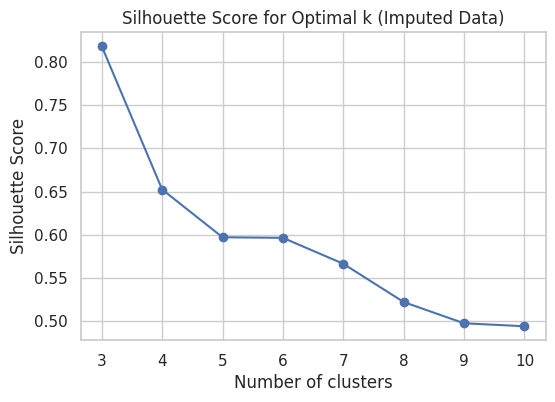

In [ ]:
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Prepare your feature set
X = df[['bmi_scaled', 'bmr_scaled']]
# Impute missing values using the mean strategy
imputer = SimpleImputer(strategy='mean')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
# Use the imputed data for clustering
silhouette_scores = {}
for k in range(3, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_imputed)
    score = silhouette_score(X_imputed, labels)
    silhouette_scores[k] = score
# Plotting (optional)
plt.figure(figsize=(6, 4))
plt.plot(silhouette_scores.keys(), silhouette_scores.values(), marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Optimal k (Imputed Data)')
plt.show()


In [ ]:
# Choose the best k (the one with the maximum silhouette score)
best_k = max(silhouette_scores, key=silhouette_scores.get)
print("Best k based on silhouette score:", best_k)
#print the best silhouette score
print("Best silhouette score:", silhouette_scores[best_k])

Best k based on silhouette score: 3
Best silhouette score: 0.8182997547663552


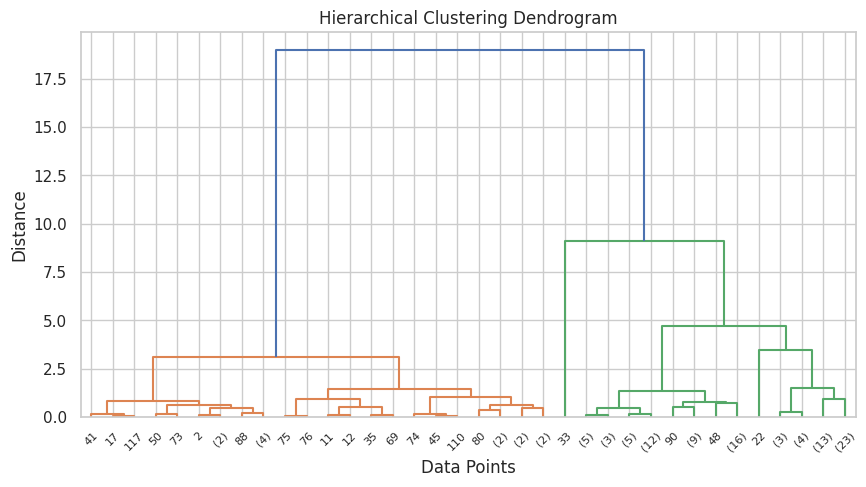

Silhouette Score for 3 clusters: 0.8120
Silhouette Score for 4 clusters: 0.6336


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Perform hierarchical clustering
Z = linkage(X_imputed, method='ward')

# Plot dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode='level', p=5)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

# Evaluate silhouette scores for 3 and 4 clusters
for n_clusters in [3, 4]:
    # Removed the 'affinity' argument as it's not needed for 'ward' linkage
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    hierarchical_labels = agg_clustering.fit_predict(X_imputed)

    silhouette_avg = silhouette_score(X_imputed, hierarchical_labels)
    print(f"Silhouette Score for {n_clusters} clusters: {silhouette_avg:.4f}")

***Web Scraping USDA using API key***

In [ ]:
import requests
import csv
import time

# Replace with your USDA API Key
API_KEY = "syGA5KfNDSelFhhQVSAPpQuGBAfe1HRJmVV068bx"
# Number of items to fetch per request
page_size =500
total_foods_needed = 20000
max_pages = total_foods_needed // page_size
# CSV file to store results
csv_filename = "usda_food_data.csv"
# Open CSV file and write header
with open(csv_filename, mode="w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["FDC ID", "Description", "Food Category", "Nutrients"])
    # Fetch data page by page
    for page in range(1, max_pages + 1):
        url = f"https://api.nal.usda.gov/fdc/v1/foods/search?query=*&pageSize={page_size}&pageNumber={page}&api_key={API_KEY}"
        response = requests.get(url)
        if response.status_code == 200:
            data = response.json()
            foods = data.get("foods", [])
            if not foods:
                print(f"No more data found on page {page}. Stopping.")
                break
            print(f"Fetching page {page} with {len(foods)} items...")
            for food in foods:
                fdc_id = food.get("fdcId", "N/A")
                description = food.get("description", "N/A")
                category = food.get("foodCategory", "N/A")
                # Extract nutrient information
                nutrients = []
                for nutrient in food.get("foodNutrients", []):
                    nutrients.append(f"{nutrient.get('nutrientName', 'Unknown')}: {nutrient.get('value', 'N/A')} {nutrient.get('unitName', '')}")
                writer.writerow([fdc_id, description, category, "; ".join(nutrients)])
        else:
            print(f"Error fetching page {page}: {response.status_code}")
            break
        time.sleep(1)
print(f"\n Data fetching complete! Saved to '{csv_filename}'.")

Fetching page 1 with 500 items...
Fetching page 2 with 500 items...
Fetching page 3 with 500 items...
Fetching page 4 with 500 items...
Fetching page 5 with 500 items...
Fetching page 6 with 500 items...
Fetching page 7 with 500 items...
Fetching page 8 with 500 items...
Fetching page 9 with 500 items...
Fetching page 10 with 500 items...
Fetching page 11 with 500 items...
Fetching page 12 with 500 items...
Fetching page 13 with 500 items...
Fetching page 14 with 500 items...
Fetching page 15 with 500 items...
Fetching page 16 with 500 items...
Fetching page 17 with 500 items...
Fetching page 18 with 500 items...
Fetching page 19 with 500 items...
Fetching page 20 with 500 items...
Fetching page 21 with 500 items...
Fetching page 22 with 500 items...
Fetching page 23 with 500 items...
Fetching page 24 with 500 items...
Fetching page 25 with 500 items...
Fetching page 26 with 500 items...
Fetching page 27 with 500 items...
Fetching page 28 with 500 items...
Fetching page 29 with 500 ite

In [ ]:
df1=pd.read_csv('/content/usda_food_data.csv')

In [ ]:
df1

,FDC ID,Description,Food Category,Nutrients
0,167782,"Abiyuch, raw",Fruits and Fruit Juices,"Vitamin A, IU: 100 IU; Energy: 290 kJ; Carbohy..."
1,171686,"Acerola, (west indian cherry), raw",Fruits and Fruit Juices,"Energy: 134 kJ; Folic acid: 0.0 UG; Folate, DF..."
2,168384,"Alfalfa seeds, sprouted, raw",Vegetables and Vegetable Products,Folic acid: 0.0 UG; Lutein + zeaxanthin: 0.0 U...
3,170683,"Amaranth grain, cooked",Cereal Grains and Pasta,Energy: 429 kJ; Energy: 102 KCAL; Total lipid ...
4,170682,"Amaranth grain, uncooked",Cereal Grains and Pasta,"Folic acid: 0.0 UG; Vitamin D (D2 + D3), Inter..."
...,...,...,...,...
19995,2718174,2L BOTTLE CAPECOD DIET CRANBERRY DRY,Non Alcoholic Beverages - Ready to Drink,Protein: 0.0 G; Total lipid (fat): 0.0 G; Carb...
19996,2718166,2L BOTTLE CRANBERRY LIME SELTZER,Non Alcoholic Beverages - Ready to Drink,Protein: 0.0 G; Total lipid (fat): 0.0 G; Carb...
19997,2718220,2L BOTTLE CREAM,Non Alcoholic Beverages - Ready to Drink,Protein: 0.0 G; Total lipid (fat): 0.0 G; Carb...
19998,2718170,2L BOTTLE DIET CREAM,Non Alcoholic Beverages - Ready to Drink,Protein: 0.0 G; Total lipid (fat): 0.0 G; Carb...


***Cleaning***

In [ ]:
#convert this into excel sheet
df1 = pd.read_csv('/content/usda_food_data.csv')
df1.to_excel('output.xlsx', index=False)

In [ ]:
# Check missing values
missing_counts = df1.isnull().sum()
print("Missing Values:\n", missing_counts)

# Drop rows where essential columns are missing
df1.dropna(subset=["Description", "Food Category", "Nutrients"], inplace=True)

# Fill missing Nutrients with 'Unknown'
df1["Nutrients"].fillna("Unknown", inplace=True)

Missing Values:
 FDC ID             0
Description        0
Food Category    136
Nutrients        114
dtype: int64


<ipython-input-74-3fae7eb92fda>:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1["Nutrients"].fillna("Unknown", inplace=True)


In [ ]:
import re

# Function to extract nutrient values
def extract_nutrient(nutrient_str, nutrient_name):
    match = re.search(rf"{nutrient_name}: ([\d\.]+)", nutrient_str)
    return float(match.group(1)) if match else None
# Extract key nutrients
df1["Energy (kJ)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Energy"))
df1["Carbohydrates (g)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Carbohydrate"))
df1["Protein (g)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Protein"))
df1["Fat (g)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Total lipid (fat)"))
df1["Sugar (g)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Sugars, total including NLEA"))
df1["Fiber (g)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Fiber"))
df1["Vitamin A (IU)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin A"))
df1["Vitamin C (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin C"))  # Corrected column name
df1["Calcium (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Calcium"))
df1["Iron (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Iron"))
df1["Potassium (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Potassium"))
df1["Sodium (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Sodium"))
df1["Zinc (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Zinc"))
df1["Copper (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Copper"))
df1["Manganese (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Manganese"))
df1["Selenium (mcg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Selenium"))
df1["Vitamin B6 (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin B6"))
df1["Vitamin B12 (mcg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin B12"))
df1["Vitamin D (mcg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin D"))
df1["Vitamin E (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin E"))
df1["Vitamin K (mcg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Vitamin K"))
df1["Cholesterol (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Cholesterol"))
df1["Caffeine (mg)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Caffeine"))
df1["Alcohol (g)"] = df1["Nutrients"].apply(lambda x: extract_nutrient(x, "Alcohol"))
# Drop the original Nutrients column
df1.drop(columns=["Nutrients"], inplace=True)

***Data Analysis***

In [ ]:
df1["Food Category"] = df1["Food Category"].str.strip().str.title()

In [ ]:
df1.drop_duplicates(subset=["Description"], keep="first", inplace=True)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df1[["Energy (kJ)", "Carbohydrates (g)", "Protein (g)", "Fat (g)"]] = scaler.fit_transform(
    df1[["Energy (kJ)", "Carbohydrates (g)", "Protein (g)", "Fat (g)"]])
df1.head(100)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/_array_api.py:776: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmin(X, axis=axis))
/usr/local/lib/python3.11/dist-packages/sklearn/utils/_array_api.py:793: RuntimeWarning: All-NaN slice encountered
  return xp.asarray(numpy.nanmax(X, axis=axis))


,FDC ID,Description,Food Category,Energy (kJ),Carbohydrates (g),Protein (g),Fat (g),Sugar (g),Fiber (g),Vitamin A (IU),...,Manganese (mg),Selenium (mcg),Vitamin B6 (mg),Vitamin B12 (mcg),Vitamin D (mcg),Vitamin E (mg),Vitamin K (mcg),Cholesterol (mg),Caffeine (mg),Alcohol (g)
0,167782,"Abiyuch, raw",Fruits And Fruit Juices,0.024576,NaN,0.016988,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,NaN,NaN,None
1,171686,"Acerola, (west indian cherry), raw",Fruits And Fruit Juices,0.011356,NaN,0.004530,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,NaN,None
2,168384,"Alfalfa seeds, sprouted, raw",Vegetables And Vegetable Products,0.008136,NaN,0.045187,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,0.0,None
3,170683,"Amaranth grain, cooked",Cereal Grains And Pasta,0.036356,NaN,0.043035,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,NaN,NaN,None
4,170682,"Amaranth grain, uncooked",Cereal Grains And Pasta,0.131356,NaN,0.154020,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,NaN,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,173952,"Carissa, (natal-plum), raw",Fruits And Fruit Juices,0.021949,NaN,0.005663,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,NaN,None
97,173755,Carob flour,Legumes And Legume Products,0.018814,NaN,0.052322,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,0.0,None
98,168568,"Carrots, baby, raw",Vegetables And Vegetable Products,0.002966,NaN,0.007248,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,NaN,None
99,170393,"Carrots, raw",Vegetables And Vegetable Products,0.003475,NaN,0.010532,NaN,None,None,NaN,...,None,None,None,None,None,NaN,None,0.0,0.0,None


In [ ]:
# Count NaN values per column
nan_counts = df1.isna().sum()
# Get total number of rows
total_rows = df1.shape[0]
# Count zeros per column
zero_counts = (df1 == 0).sum()
# Compute total missing (NaN + 0)
total_missing = nan_counts + zero_counts
# Calculate the percentage of missing values
missing_percent = (total_missing / total_rows) * 100
# Combine results into a DataFrame
summary = pd.DataFrame({
    "NaN Count": nan_counts,
    "Zero Count": zero_counts,
    "Total Missing": total_missing,
    "Total Rows": total_rows,
     "Missing Percentage": missing_percent
})
# Display results
print(summary)

                   NaN Count  Zero Count  Total Missing  Total Rows  \
FDC ID                     0           0              0       17064   
Description                0           0              0       17064   
Food Category              0           0              0       17064   
Energy (kJ)              219         397            616       17064   
Carbohydrates (g)      17064           0          17064       17064   
Protein (g)               28        1751           1779       17064   
Fat (g)                17064           0          17064       17064   
Sugar (g)              17064           0          17064       17064   
Fiber (g)              17064           0          17064       17064   
Vitamin A (IU)         16909          71          16980       17064   
Vitamin C (mg)         17064           0          17064       17064   
Calcium (mg)           17064           0          17064       17064   
Iron (mg)              17064           0          17064       17064   
Potass

In [ ]:
# Set threshold
threshold = 50
cols_to_drop = missing_percent[missing_percent > threshold].index.tolist()
print("Dropping columns:", cols_to_drop)
# Drop these columns
df1= df1.drop(columns=cols_to_drop)

Dropping columns: ['Carbohydrates (g)', 'Fat (g)', 'Sugar (g)', 'Fiber (g)', 'Vitamin A (IU)', 'Vitamin C (mg)', 'Calcium (mg)', 'Iron (mg)', 'Potassium (mg)', 'Sodium (mg)', 'Zinc (mg)', 'Copper (mg)', 'Manganese (mg)', 'Selenium (mcg)', 'Vitamin B6 (mg)', 'Vitamin B12 (mcg)', 'Vitamin D (mcg)', 'Vitamin E (mg)', 'Vitamin K (mcg)', 'Caffeine (mg)', 'Alcohol (g)']


***Feature Engineering***

In [ ]:
import pandas as pd
import numpy as np


# Calculate quantile thresholds for Energy (kJ) and Protein (g)
energy_low = df1["Energy (kJ)"].quantile(0.33)
energy_high = df1["Energy (kJ)"].quantile(0.67)
protein_low = df1["Protein (g)"].quantile(0.33)
protein_high = df1["Protein (g)"].quantile(0.67)
print("Energy low (33rd percentile):", energy_low)
print("Energy high (67th percentile):", energy_high)
print("Protein low (33rd percentile):", protein_low)
print("Protein high (67th percentile):", protein_high)

def categorize_nutritional_goal(row):
    energy = row["Energy (kJ)"]
    protein = row["Protein (g)"]
    cholesterol = row["Cholesterol (mg)"]
    # If critical values are missing, return "Unknown"
    if pd.isna(energy) or pd.isna(protein):
        return "Unknown"
    # Define Weight Loss as: energy below the lower threshold and protein at least moderate
    if energy < energy_low and protein >= protein_low:
        return "Weight Loss"
    # Define Weight Gain as: energy above the upper threshold and protein above the upper threshold
    if energy > energy_high and protein >= protein_high:
        return "Weight Gain"
    # Define Maintenance as: energy between the thresholds and protein at least moderate
    if energy >= energy_low and energy <= energy_high and protein >= protein_low:
        return "Maintenance"
    # Otherwise, assign "Other"
    return "Maintenance"
# Apply the categorization function row-wise
df1["Nutrition_Category"] = df1.apply(categorize_nutritional_goal, axis=1)
# Show the count for each category
print(df1["Nutrition_Category"].value_counts())
# Optionally, preview the first few rows with the new column
df1.head()

Energy low (33rd percentile): 0.011779661016949154
Energy high (67th percentile): 0.03152542372881356
Protein low (33rd percentile): 0.031257078142695356
Protein high (67th percentile): 0.13413929784824472
Nutrition_Category
Maintenance    12292
Weight Gain     2587
Weight Loss     1954
Unknown          231
Name: count, dtype: int64


,FDC ID,Description,Food Category,Energy (kJ),Protein (g),Cholesterol (mg),Nutrition_Category
0,167782,"Abiyuch, raw",Fruits And Fruit Juices,0.024576,0.016988,NaN,Maintenance
1,171686,"Acerola, (west indian cherry), raw",Fruits And Fruit Juices,0.011356,0.004530,0.0,Maintenance
2,168384,"Alfalfa seeds, sprouted, raw",Vegetables And Vegetable Products,0.008136,0.045187,0.0,Weight Loss
3,170683,"Amaranth grain, cooked",Cereal Grains And Pasta,0.036356,0.043035,NaN,Maintenance
4,170682,"Amaranth grain, uncooked",Cereal Grains And Pasta,0.131356,0.154020,0.0,Weight Gain


In [ ]:
df1["Nutrition_Category"].value_counts()

,count
Nutrition_Category,
Maintenance,12292
Weight Gain,2587
Weight Loss,1954
Unknown,231


In [ ]:
#save df1 dataset in csv
df1.to_csv('food_dataset.csv', index=False)

***Chatbot***

In [ ]:
import pandas as pd
import random

def compute_bmi(weight, height_cm):
    height_m = height_cm / 100.0
    bmi = weight / (height_m ** 2)
    return bmi
def classify_bmi(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal weight"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obesity"
def assign_cluster(bmi):
    if bmi < 18.5:
        return 0
    elif bmi < 25:
        return 1
    elif bmi < 30:
        return 2
    else:
        return 3

def cluster_to_internal_category(cluster):
    if cluster == 0:
        return "Weight Gain"
    elif cluster == 1:
        return "Normal"
    elif cluster == 2:
        return "Weight Loss"
    elif cluster == 3:
        return "Weight Loss"

def convert_cluster_recommendation_to_goal(cluster_rec):
    if cluster_rec == "Weight Loss":
        return "loss"
    elif cluster_rec == "Weight Gain":
        return "gain"
    else:
        return "maintenance"

def get_calorie_range(bmi_category, activity_level, goal):
    activity = activity_level.lower()
    if bmi_category in ["Normal weight", "Underweight"]:
        if activity == "sedentary":
            base = (1600, 2000)
        elif activity == "moderately active":
            base = (2000, 2400)
        elif activity == "very active":
            base = (2400, 3000)
        else:
            base = (1600, 2000)
    elif bmi_category in ["Overweight", "Obesity"]:
        if activity == "sedentary":
            base = (1200, 1800)
        elif activity == "moderately active":
            base = (1600, 2200)
        elif activity == "very active":
            base = (2000, 2600)
        else:
            base = (1200, 1800)
    else:
        base = (1600, 2000)
    if goal == "loss":
        adjusted = (max(base[0]-500, 1200), max(base[1]-500, 1500))
    elif goal == "gain":
        adjusted = (base[0] + 250, base[1] + 500)
    else:
        adjusted = base
    return adjusted

def map_goal_to_internal_category(goal):
    if goal == 'loss':
        return "Weight Loss"
    elif goal == 'gain':
        return "Weight Gain"
    else:
        return "Normal"

def get_meal_recommendations(internal_category, food_dataset_path='food_dataset.csv'):
    try:
        food_df = pd.read_csv(food_dataset_path)
    except Exception as e:
        print(f"Oops! I had trouble loading the food data: {e}")
        return None
    required_columns = ['FDC ID', 'Description', 'Food Category', 'Energy (kJ)',
                        'Protein (g)', 'Cholesterol (mg)', 'Nutrition_Category']
    for col in required_columns:
        if col not in food_df.columns:
            print(f"Missing required info: {col}")
            return None
    # Filter by internal category (case-insensitive)
    filtered_food = food_df[food_df['Nutrition_Category'].str.lower() == internal_category.lower()]
    if filtered_food.empty:
        print("I couldn't find food items for your goal, so I'll use the full list instead.")
        filtered_food = food_df
    filtered_food.loc[:, 'Protein (g)'] = pd.to_numeric(filtered_food['Protein (g)'], errors='coerce')
    breakfast_df = filtered_food.dropna(subset=['Protein (g)'])
    if not breakfast_df.empty:
        breakfast_choice = breakfast_df.loc[breakfast_df['Protein (g)'].idxmax()]
    else:
        breakfast_choice = filtered_food.sample(n=1).iloc[0]
    lunch_choice = filtered_food.sample(n=1).iloc[0]
    filtered_food.loc[:, 'Cholesterol (mg)'] = pd.to_numeric(filtered_food['Cholesterol (mg)'], errors='coerce')
    dinner_candidates = filtered_food[filtered_food['Cholesterol (mg)'].fillna(0) == 0]
    if not dinner_candidates.empty:
        dinner_choice = dinner_candidates.sample(n=1).iloc[0]
    else:
        dinner_choice = filtered_food.sample(n=1).iloc[0]
    meal_plan = {
        'breakfast': breakfast_choice.to_dict(),
        'lunch': lunch_choice.to_dict(),
        'dinner': dinner_choice.to_dict()
    }
    return meal_plan
def main():
    print("Hi there! I'm your friendly nutrition chatbot. Let's chat about your health and meal planning.\n")
    try:
        weight = float(input("First, could you please tell me your weight in kg? "))
        height_cm = float(input("Great, and what is your height in cm? "))
    except ValueError:
        print("Oops! That doesn't look like a valid number. Please try again with numeric values.")
        return
    # Validate activity level input
    print("\nThanks! Now, could you tell me your activity level?")
    print("  1: Sedentary (little or no exercise)")
    print("  2: Moderately Active (some exercise)")
    print("  3: Very Active (lots of exercise)")
    activity_mapping = {'1': 'sedentary', '2': 'moderately active', '3': 'very active'}
    while True:
        activity_choice = input("Please enter the number corresponding to your activity level (1, 2, or 3): ").strip()
        if activity_choice in ['1', '2', '3']:
            break
        else:
            print("Oops! That's not a valid option. Please try again using 1, 2, or 3.")
    activity_level = activity_mapping.get(activity_choice, 'sedentary')
    # Validate dietary goal input
    print("\nAwesome! Now, what's your dietary goal?")
    print("  1: Weight Loss")
    print("  2: Weight Maintenance (I'll call this Normal)")
    print("  3: Muscle Gain")
    dietary_mapping = {'1': 'loss', '2': 'maintenance', '3': 'gain'}
    while True:
        dietary_choice = input("Please enter the number corresponding to your dietary goal (1, 2, or 3): ").strip()
        if dietary_choice in ['1', '2', '3']:
            break
        else:
            print("Sorry, I didn't catch that. Please choose 1, 2, or 3.")
    goal = dietary_mapping.get(dietary_choice, 'maintenance')
    bmi = compute_bmi(weight, height_cm)
    bmi_category = classify_bmi(bmi)
    print(f"\nThanks for sharing! Your BMI is {bmi:.2f}, which means you're categorized as {bmi_category}.")
    # Cluster the user based on BMI
    cluster = assign_cluster(bmi)
    print(f"I'm placing you in cluster {cluster} based on your BMI.")
    # Get cluster recommendation and compare it with user's goal
    cluster_rec = cluster_to_internal_category(cluster)
    print(f"My analysis suggests that a good approach for you is: {cluster_rec}.")
    user_internal_category = map_goal_to_internal_category(goal)
    print(f"You chose: {user_internal_category}.")
    if user_internal_category != cluster_rec:
        warning_choice = input(
            f"\nIt seems my recommendation is '{cluster_rec}', while you chose '{user_internal_category}'.\n"
            "Would you like to switch to my recommendation? (Enter 1 for Yes, 2 for No): "
        )
        if warning_choice.strip() == "1":
            goal = convert_cluster_recommendation_to_goal(cluster_rec)
            print(f"Alright, I'll adjust your goal to '{cluster_rec}' for you.\n")
        else:
            print("Okay, we'll proceed with your original choice.\n")
    # Additional friendly advice for certain BMI categories
    if bmi_category == "Normal weight" and goal in ["loss", "gain"]:
        warning_choice = input(
            "\nYou're at a normal weight, so maintaining might be the healthiest option.\n"
            "Would you like to switch to weight maintenance? (Enter 1 for Yes, 2 for No): "
        )
        if warning_choice.strip() == "1":
            goal = "maintenance"
            print("Great! We'll set your goal to weight maintenance.\n")
        else:
            print("No problem, we'll stick with your chosen goal.\n")
    if bmi_category == "Underweight" and goal == "loss":
        warning_choice = input(
            "\nYou're underweight, so losing more might not be a good idea.\n"
            "Would you prefer to maintain (enter 1) or gain weight (enter 2)? "
        )
        if warning_choice.strip() == "1":
            goal = "maintenance"
            print("Okay, we'll aim for maintaining your current weight.\n")
        else:
            goal = "gain"
            print("Alright, let's aim to help you gain some healthy weight.\n")
    if bmi_category == "Obesity" and goal == "gain":
        warning_choice = input(
            "\nSince you're in the obesity range, losing weight is generally advised before considering gain.\n"
            "Would you like to switch to weight loss (enter 1) or continue with weight gain (enter 2)? "
        )
        if warning_choice.strip() == "1":
            goal = "loss"
            print("Understood, we'll focus on weight loss for your health.\n")
        else:
            print("Okay, proceeding with your chosen goal.\n")
    calorie_range = get_calorie_range(bmi_category, activity_level, goal)
    print(f"Based on our chat, your recommended daily calorie range is: {calorie_range[0]} - {calorie_range[1]} calories.\n")
    # Now let's get you a meal plan
    internal_category = map_goal_to_internal_category(goal)
    meal_plan = get_meal_recommendations(internal_category, food_dataset_path='food_dataset.csv')
    if meal_plan:
        # Remove internal category detail before printing
        for meal in meal_plan:
            meal_plan[meal].pop('Nutrition_Category', None)
        print("Here's a meal plan recommendation for you:")
        print("\nBreakfast:")
        for key, value in meal_plan['breakfast'].items():
            print(f"  {key}: {value}")
        print("\nLunch:")
        for key, value in meal_plan['lunch'].items():
            print(f"  {key}: {value}")
        print("\nDinner:")
        for key, value in meal_plan['dinner'].items():
            print(f"  {key}: {value}")
    else:
        print("Sorry, I couldn't generate a meal plan for you at the moment.")
if __name__ == '__main__':
    main()

Hi there! I'm your friendly nutrition chatbot. Let's chat about your health and meal planning.

First, could you please tell me your weight in kg? 85
Great, and what is your height in cm? 168

Thanks! Now, could you tell me your activity level?
  1: Sedentary (little or no exercise)
  2: Moderately Active (some exercise)
  3: Very Active (lots of exercise)
Please enter the number corresponding to your activity level (1, 2, or 3): 2

Awesome! Now, what's your dietary goal?
  1: Weight Loss
  2: Weight Maintenance (I'll call this Normal)
  3: Muscle Gain
Please enter the number corresponding to your dietary goal (1, 2, or 3): 2

Thanks for sharing! Your BMI is 30.12, which means you're categorized as Obesity.
I'm placing you in cluster 3 based on your BMI.
My analysis suggests that a good approach for you is: Weight Loss.
You chose: Normal.

It seems my recommendation is 'Weight Loss', while you chose 'Normal'.
Would you like to switch to my recommendation? (Enter 1 for Yes, 2 for No): 1